Integrantes: María Adelaida Restrepo, Juanita Arenas, Michelle Ruiz, Sofía Berrío y Jerónimo Morales.

# **SISTEMA EXPERTO: Proyecto de Reclutamiento**


**Figura 1**

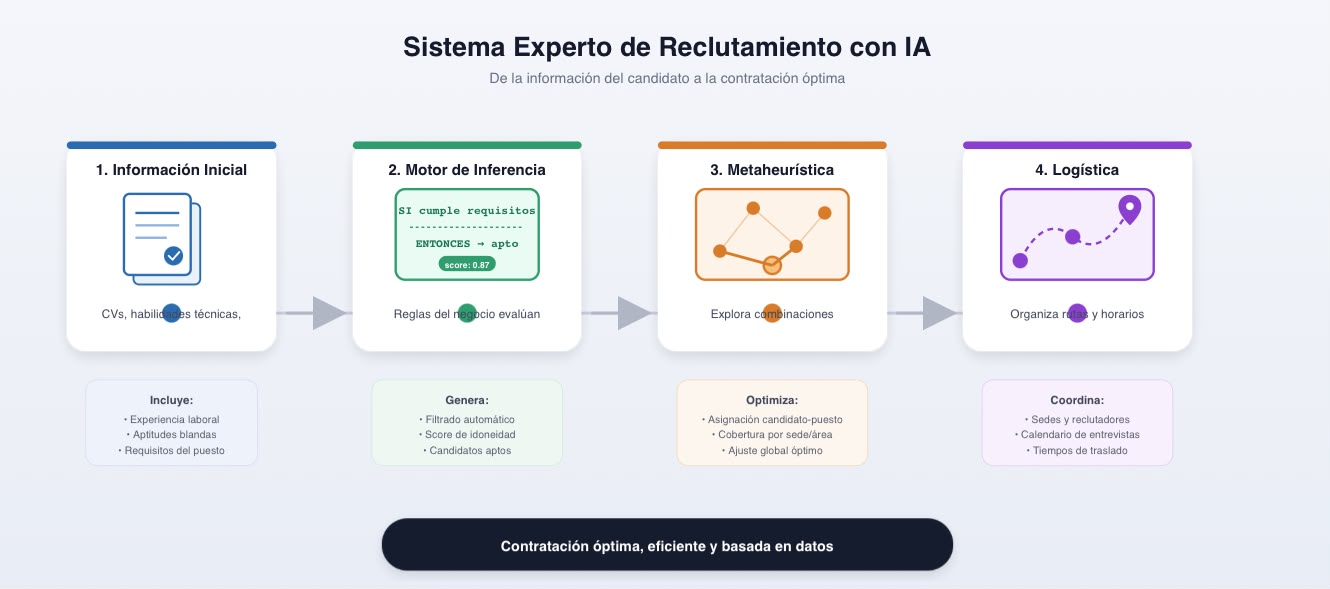

Figura 2:

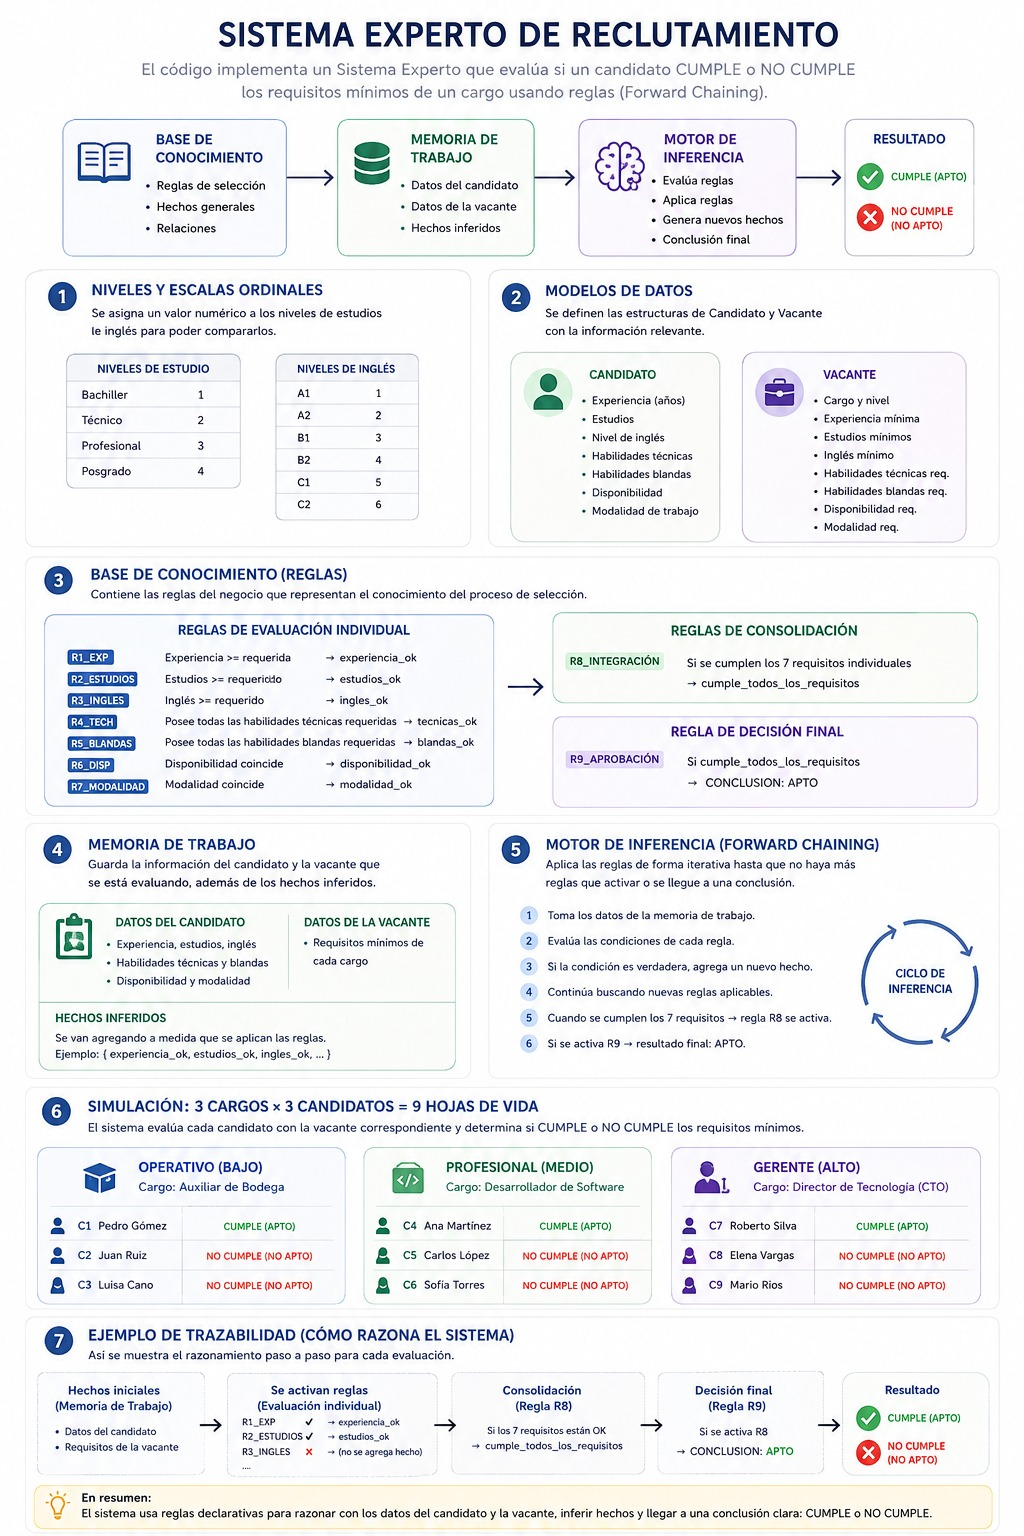

In [ ]:
from typing import List, Dict, Set, Callable
from dataclasses import dataclass, field #dataclasses para crear plantillas

# ==========================================
# 0. NIVELES Y ESCALAS ORDINALES
# ==========================================
# Mapeo numérico para comparar niveles de estudio e inglés
NIVELES_ESTUDIO = {"Bachiller": 1, "Técnico": 2, "Profesional": 3, "Posgrado": 4} #asigna pesos a cada nivel
NIVELES_INGLES = {"A1": 1, "A2": 2, "B1": 3, "B2": 4, "C1": 5, "C2": 6}

# ==========================================
# 1. MODELOS DE DATOS
# ==========================================
@dataclass #plantilla del currículum  #el @ es el decorador, que nos ahorra escribir más código --> guarda datos y compara
class Candidato:
    id_candidato: str
    nombre: str
    experiencia_anos: float
    estudios: str          # Bachiller, Técnico, Profesional, Posgrado
    nivel_ingles: str       # A1, A2, B1, B2, C1, C2
    hab_tecnicas: List[str]
    hab_blandas: List[str]
    disponibilidad: str     # Ej: "Tiempo Completo", "Medio Tiempo"
    modalidad: str          # Ej: "Presencial", "Remoto", "Híbrido"

@dataclass #plantilla de lo que exige la empresa
class Vacante:
    id_vacante: str
    cargo: str
    nivel_cargo: str        # Operativo, Profesional, Gerente
    exp_minima: float
    estudios_minimos: str
    ingles_minimo: str
    hab_tecnicas_req: List[str]
    hab_blandas_req: List[str]
    disponibilidad_req: str
    modalidad_req: str

# ==========================================
# 2. ESTRUCTURA DE REGLAS Y BASE DE CONOCIMIENTO
# ==========================================
class Regla:
    """Representa una regla lógica SI (antecedentes) -> ENTONCES (consecuente)."""
    def __init__(self, id_regla: str, descripcion: str,
                 condicion: Callable[['MemoriaDeTrabajo'], bool],
                 consecuente_hecho: str):
        self.id_regla = id_regla
        self.descripcion = descripcion
        self.condicion = condicion
        self.consecuente_hecho = consecuente_hecho

class BaseDeConocimiento:
    """Contiene todas las reglas de negocio declarativas del Sistema Experto."""
    def __init__(self):
        self.reglas: List[Regla] = []
        self._cargar_reglas()

    def _cargar_reglas(self):
        # -------------------------------------------------------------
        # FASE 1: REGLAS DE EVALUACIÓN INDIVIDUAL DE REQUISITOS (FACHADA)
        # -------------------------------------------------------------
        self.reglas.append(Regla(
            id_regla="R1_EXP",
            descripcion="SI la experiencia laboral es >= a la requerida ENTONCES la experiencia es suficiente",
            condicion=lambda mt: mt.candidato.experiencia_anos >= mt.vacante.exp_minima,
            consecuente_hecho="experiencia_ok"
        ))

        self.reglas.append(Regla(
            id_regla="R2_ESTUDIOS",
            descripcion="SI el nivel de estudios es >= al requerido ENTONCES los estudios cumplen",
            condicion=lambda mt: NIVELES_ESTUDIO.get(mt.candidato.estudios, 0) >= NIVELES_ESTUDIO.get(mt.vacante.estudios_minimos, 0),
            consecuente_hecho="estudios_ok"
        ))

        self.reglas.append(Regla(
            id_regla="R3_INGLES",
            descripcion="SI el nivel de inglés es >= al requerido ENTONCES el idioma cumple",
            condicion=lambda mt: NIVELES_INGLES.get(mt.candidato.nivel_ingles, 0) >= NIVELES_INGLES.get(mt.vacante.ingles_minimo, 0),
            consecuente_hecho="ingles_ok"
        ))

        self.reglas.append(Regla(
            id_regla="R4_TECH",
            descripcion="SI posee TODAS las habilidades técnicas requeridas ENTONCES la parte técnica cumple",
            condicion=lambda mt: set(mt.vacante.hab_tecnicas_req).issubset(set(mt.candidato.hab_tecnicas)),
            consecuente_hecho="tecnicas_ok"
        ))

        self.reglas.append(Regla(
            id_regla="R5_BLANDAS",
            descripcion="SI posee TODAS las habilidades blandas requeridas ENTONCES la parte actitudinal cumple",
            condicion=lambda mt: set(mt.vacante.hab_blandas_req).issubset(set(mt.candidato.hab_blandas)),
            consecuente_hecho="blandas_ok"
        ))

        self.reglas.append(Regla(
            id_regla="R6_DISP",
            descripcion="SI la disponibilidad horaria coincide ENTONCES la disponibilidad cumple",
            condicion=lambda mt: mt.candidato.disponibilidad == mt.vacante.disponibilidad_req,
            consecuente_hecho="disponibilidad_ok"
        ))

        self.reglas.append(Regla(
            id_regla="R7_MODALIDAD",
            descripcion="SI la modalidad de trabajo coincide ENTONCES la modalidad cumple",
            condicion=lambda mt: mt.candidato.modalidad == mt.vacante.modalidad_req,
            consecuente_hecho="modalidad_ok"
        ))

        # -------------------------------------------------------------
        # FASE 2: REGLAS DE CONSOLIDACIÓN (FORWARD CHAINING NIVELES SUPERIORES)
        # -------------------------------------------------------------
        hechos_requeridos = { #checklist
            "experiencia_ok", "estudios_ok", "ingles_ok",
            "tecnicas_ok", "blandas_ok", "disponibilidad_ok", "modalidad_ok"
        }

        self.reglas.append(Regla(  #supervisa que el candidato cumpla con la checklist
            id_regla="R8_INTEGRACION_POSITIVA",
            descripcion="SI se cumplen individualmente los 7 requisitos ENTONCES cumple todos los requisitos mínimos",
            condicion=lambda mt: hechos_requeridos.issubset(mt.hechos),
            consecuente_hecho="cumple_todos_los_requisitos"
        ))

        # -------------------------------------------------------------
        # FASE 3: REGLA DE DECISIÓN FINAL
        # -------------------------------------------------------------
        self.reglas.append(Regla(
            id_regla="R9_APROBACION",
            descripcion="SI cumple todos los requisitos mínimos ENTONCES la conclusión es APTO",
            condicion=lambda mt: "cumple_todos_los_requisitos" in mt.hechos,
            consecuente_hecho="CONCLUSION: APTO"
        ))

# ==========================================
# 3. MEMORIA DE TRABAJO
# ==========================================
class MemoriaDeTrabajo: #esta es como la evaluación. Toma cada currículum y oferta de trabajo una por una.
    """Guarda el contexto actual de la evaluación y los hechos inferidos."""
    def __init__(self, candidato: Candidato, vacante: Vacante):
        self.candidato = candidato
        self.vacante = vacante
        self.hechos: Set[str] = set()
        self.trazabilidad: List[str] = []

    def agregar_hecho(self, hecho: str, regla_id: str):
        if hecho not in self.hechos:
            self.hechos.add(hecho)
            self.trazabilidad.append(f"Regla [{regla_id}] activada -> Hecho inferido: '{hecho}'")

# ==========================================
# 4. MOTOR DE INFERENCIA (FORWARD CHAINING)
# ==========================================
class MotorDeInferencia:
    """Aplica las reglas sobre la memoria de trabajo mediante Encadenamiento Hacia Adelante."""
    def __init__(self, bc: BaseDeConocimiento):
        self.bc = bc

    def evaluar(self, candidato: Candidato, vacante: Vacante) -> Dict:
        # Inicializar Memoria de Trabajo para el candidato actual
        mt = MemoriaDeTrabajo(candidato, vacante)
        reglas_aplicadas: Set[str] = set()

        # Bucle Forward Chaining: Continúa ejecutando reglas mientras se deduzcan nuevos hechos, ya que empezó la entrevista.
        hubo_cambio = True #Forward Chaining: si hubo cambio = reglas nuevas del candidato --> vuelve a leer libro por si se activa regla nueva --> no regla nueva = while se detiene.
        while hubo_cambio:
            hubo_cambio = False
            for regla in self.bc.reglas:
                # Si la regla no ha sido aplicada y su condición es verdadera
                if regla.id_regla not in reglas_aplicadas:
                    if regla.condicion(mt):
                        mt.agregar_hecho(regla.consecuente_hecho, regla.id_regla)
                        reglas_aplicadas.add(regla.id_regla)
                        hubo_cambio = True  # Hubo un nuevo hecho inferido, continuar el bucle

        # Determinar resultado final
        es_apto = "CONCLUSION: APTO" in mt.hechos
        resultado = "CUMPLE (APTO)" if es_apto else "NO CUMPLE (NO APTO)"

        # Detectar qué falló (si no fue apto)
        fallos = []
        hechos_esperados = {
            "experiencia_ok": "Experiencia laboral insuficiente",
            "estudios_ok": "Nivel de estudios inferior al requerido",
            "ingles_ok": "Nivel de inglés insuficiente",
            "tecnicas_ok": "Faltan habilidades técnicas requeridas",
            "blandas_ok": "Faltan habilidades blandas requeridas",
            "disponibilidad_ok": "Disponibilidad horaria incompatible",
            "modalidad_ok": "Modalidad de trabajo incompatible"
        }

        for hecho_req, desc_fallo in hechos_esperados.items():
            if hecho_req not in mt.hechos:
                fallos.append(desc_fallo)

        return {
            "candidato": candidato.nombre,
            "cargo": vacante.cargo,
            "resultado": resultado,
            "trazabilidad": mt.trazabilidad,
            "fallos": fallos
        }

# ==========================================
# 5. SIMULACIÓN Y PRUEBAS (3 CARGOS x 3 CANDIDATOS)
# ==========================================
if __name__ == "__main__":
    # --- VACANTES DE PRUEBA (3 NIVELES) ---
    vacantes = [
        Vacante(
            id_vacante="V1", cargo="Auxiliar de Bodega", nivel_cargo="Operativo",
            exp_minima=0.5, estudios_minimos="Bachiller", ingles_minimo="A1",
            hab_tecnicas_req=["Manejo de Inventario"], hab_blandas_req=["Puntualidad", "Trabajo en Equipo"],
            disponibilidad_req="Tiempo Completo", modalidad_req="Presencial"
        ),
        Vacante(
            id_vacante="V2", cargo="Desarrollador de Software", nivel_cargo="Profesional",
            exp_minima=3.0, estudios_minimos="Profesional", ingles_minimo="B2",
            hab_tecnicas_req=["Python", "SQL", "Git"], hab_blandas_req=["Comunicación Asertiva", "Resolución de Problemas"],
            disponibilidad_req="Tiempo Completo", modalidad_req="Híbrido"
        ),
        Vacante(
            id_vacante="V3", cargo="Director de Tecnología (CTO)", nivel_cargo="Gerente",
            exp_minima=8.0, estudios_minimos="Posgrado", ingles_minimo="C1",
            hab_tecnicas_req=["Arquitectura de Software", "Presupuestos"], hab_blandas_req=["Liderazgo", "Negociación"],
            disponibilidad_req="Tiempo Completo", modalidad_req="Presencial"
        )
    ]

    # --- 9 CANDIDATOS DE PRUEBA ---
    candidatos = [
        # Operativos
        Candidato("C1", "Pedro Gómez (Operativo 1)", 1.0, "Bachiller", "A1", ["Manejo de Inventario"], ["Puntualidad", "Trabajo en Equipo"], "Tiempo Completo", "Presencial"),
        Candidato("C2", "Juan Ruiz (Operativo 2)", 0.2, "Bachiller", "A1", ["Manejo de Inventario"], ["Puntualidad", "Trabajo en Equipo"], "Tiempo Completo", "Presencial"), # Falta exp
        Candidato("C3", "Luisa Cano (Operativo 3)", 2.0, "Bachiller", "A1", ["Manejo de Inventario"], ["Trabajo en Equipo"], "Medio Tiempo", "Presencial"), # Falta hab. blanda y disp

        # Profesionales
        Candidato("C4", "Ana Martínez (Profesional 1)", 4.0, "Profesional", "B2", ["Python", "SQL", "Git"], ["Comunicación Asertiva", "Resolución de Problemas"], "Tiempo Completo", "Híbrido"),
        Candidato("C5", "Carlos López (Profesional 2)", 5.0, "Profesional", "A2", ["Python", "SQL", "Git"], ["Comunicación Asertiva", "Resolución de Problemas"], "Tiempo Completo", "Híbrido"), # Falta inglés
        Candidato("C6", "Sofía Torres (Profesional 3)", 1.5, "Técnico", "B2", ["Python"], ["Comunicación Asertiva", "Resolución de Problemas"], "Tiempo Completo", "Híbrido"), # Falta exp, estudios, tech

        # Gerentes
        Candidato("C7", "Roberto Silva (Gerente 1)", 10.0, "Posgrado", "C1", ["Arquitectura de Software", "Presupuestos"], ["Liderazgo", "Negociación"], "Tiempo Completo", "Presencial"),
        Candidato("C8", "Elena Vargas (Gerente 2)", 9.0, "Profesional", "C1", ["Arquitectura de Software", "Presupuestos"], ["Liderazgo", "Negociación"], "Tiempo Completo", "Presencial"), # Falta estudios posgrado
        Candidato("C9", "Mario Rios (Gerente 3)", 6.0, "Posgrado", "B2", ["Presupuestos"], ["Liderazgo"], "Tiempo Completo", "Remoto") # Falta exp, inglés, tech, blanda, modalidad
    ]

    # Instanciar Base de Conocimiento y Motor de Inferencia
    bc = BaseDeConocimiento()
    motor = MotorDeInferencia(bc)

    print("==================================================================================")
    print("      DEMOSTRACIÓN: SISTEMA EXPERTO DE RECLUTAMIENTO (FORWARD CHAINING)          ")
    print("==================================================================================\n")

    # Mapeo de evaluación: 3 candidatos por cada vacante
    evaluaciones = [
        (candidatos[0], vacantes[0]), (candidatos[1], vacantes[0]), (candidatos[2], vacantes[0]),
        (candidatos[3], vacantes[1]), (candidatos[4], vacantes[1]), (candidatos[5], vacantes[1]),
        (candidatos[6], vacantes[2]), (candidatos[7], vacantes[2]), (candidatos[8], vacantes[2])
    ]

    for cand, vac in evaluaciones:
        res = motor.evaluar(cand, vac)

        print(f"CARGO EVALUADO: {vac.cargo} ({vac.nivel_cargo})")
        print(f"CANDIDATO: {cand.nombre}")
        print(f"RESULTADO FINAL: >>> {res['resultado']} <<<")

        print("Trazabilidad de Reglas Disparadas (Forward Chaining):")
        for paso in res['trazabilidad']:
            print(f"   ├─ {paso}")

        if res['fallos']:
            print("Requisitos No Cumplidos:")
            for fallo in res['fallos']:
                print(f"   └─ [X] {fallo}")
        print("-" * 80)

      DEMOSTRACIÓN: SISTEMA EXPERTO DE RECLUTAMIENTO (FORWARD CHAINING)          

CARGO EVALUADO: Auxiliar de Bodega (Operativo)
CANDIDATO: Pedro Gómez (Operativo 1)
RESULTADO FINAL: >>> CUMPLE (APTO) <<<
Trazabilidad de Reglas Disparadas (Forward Chaining):
   ├─ Regla [R1_EXP] activada -> Hecho inferido: 'experiencia_ok'
   ├─ Regla [R2_ESTUDIOS] activada -> Hecho inferido: 'estudios_ok'
   ├─ Regla [R3_INGLES] activada -> Hecho inferido: 'ingles_ok'
   ├─ Regla [R4_TECH] activada -> Hecho inferido: 'tecnicas_ok'
   ├─ Regla [R5_BLANDAS] activada -> Hecho inferido: 'blandas_ok'
   ├─ Regla [R6_DISP] activada -> Hecho inferido: 'disponibilidad_ok'
   ├─ Regla [R7_MODALIDAD] activada -> Hecho inferido: 'modalidad_ok'
   ├─ Regla [R8_INTEGRACION_POSITIVA] activada -> Hecho inferido: 'cumple_todos_los_requisitos'
   ├─ Regla [R9_APROBACION] activada -> Hecho inferido: 'CONCLUSION: APTO'
--------------------------------------------------------------------------------
CARGO EVALUADO: Auxi

Las figuras 1 y 2 fueron generadas por ChatGPT https://chatgpt.com/c/6a91981a-416c-83e9-8786-a1fbb1c8d0f8

Codigo generado por Gemini https://gemini.google.com/app/7e4f326f3adef206